# Chapter 4. Implementation
## 4.6 Noise-Level Estimation
### 4.6.3 Flat-Region Fraction Selection

The flat-region fraction is tuned on the calibration set. The selected estimator is then compared with the original Laplacian estimator.


## 1. Experiment Setup

The same 50 calibration images and seven noise levels are used.


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.noise import add_gaussian_noise
from src.noise_level_estimators import edge_aware_laplacian_noise_estimate, laplacian_noise_estimate
from src.utils import load_grayscale_image


In [2]:
# Experiment settings
noise_levels = [2, 4, 6, 8, 10, 12, 15]
seed = 42
num_calibration = 50
flat_fraction_candidates = [0.03, 0.04, 0.05, 0.06, 0.07]
n_jobs = 12
selection_metric = "mean_relative_error"

calibration_dir = project_dir / "data" / "calibration"
result_dir = project_dir / "results" / "Chapter4_EdgeAwareLaplacianRefinement"
result_dir.mkdir(parents=True, exist_ok=True)

print("Calibration noise levels (%):", noise_levels)
print("Random seed:", seed)
print("Flat-fraction candidates:", flat_fraction_candidates)
print("Selection metric: Overall MRE")
print("Parallel jobs:", n_jobs)


Calibration noise levels (%): [2, 4, 6, 8, 10, 12, 15]
Random seed: 42
Flat-fraction candidates: [0.03, 0.04, 0.05, 0.06, 0.07]
Selection metric: Overall MRE
Parallel jobs: 12


In [3]:
# Find all image files
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(calibration_dir.glob(pattern))

image_files = sorted(image_files)
if len(image_files) < num_calibration:
    raise FileNotFoundError(
        f"At least {num_calibration} images are required, but only {len(image_files)} were found in {calibration_dir}"
    )

# Reproduce the calibration split
split_rng = np.random.default_rng(seed)
shuffled_indices = split_rng.permutation(len(image_files))
calibration_indices = shuffled_indices[:num_calibration]
calibration_files = sorted([image_files[index] for index in calibration_indices])

calibration_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in calibration_files
}

print("Number of calibration images:", len(calibration_images))


Number of calibration images: 50


## 2. Flat-Fraction Search

Candidate flat-region fractions are compared using overall MRE.


In [4]:
# Evaluate all candidates on one image-noise case
def evaluate_calibration_case(image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    rows = []

    # Original Laplacian
    start = time.perf_counter()
    estimate = float(laplacian_noise_estimate(noisy_image)) * 100
    runtime_ms = (time.perf_counter() - start) * 1000

    rows.append({
        "image": image_name,
        "true_sigma": noise_percent,
        "estimator_label": "Original Laplacian",
        "flat_fraction": np.nan,
        "estimated_sigma": estimate,
        "runtime_ms": runtime_ms
    })

    # Edge-aware candidates
    for flat_fraction in flat_fraction_candidates:
        start = time.perf_counter()
        estimate = float(edge_aware_laplacian_noise_estimate(
            noisy_image, flat_fraction=flat_fraction
        )) * 100
        runtime_ms = (time.perf_counter() - start) * 1000

        rows.append({
            "image": image_name,
            "true_sigma": noise_percent,
            "estimator_label": f"Edge-aware ({flat_fraction:.0%})",
            "flat_fraction": flat_fraction,
            "estimated_sigma": estimate,
            "runtime_ms": runtime_ms
        })

    return rows


case_results = Parallel(n_jobs=n_jobs, prefer="threads", verbose=5)(
    delayed(evaluate_calibration_case)(image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_name, clean_image in calibration_images.items()
)

calibration_rows = [row for rows in case_results for row in rows]
calibration_results = pd.DataFrame(calibration_rows)

print("Calibration image-noise cases:", len(case_results))
print("Estimator records:", len(calibration_results))


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:    2.4s
[Parallel(n_jobs=12)]: Done 138 tasks      | elapsed:    6.6s
[Parallel(n_jobs=12)]: Done 264 tasks      | elapsed:   12.4s


Calibration image-noise cases: 350
Estimator records: 2100


[Parallel(n_jobs=12)]: Done 350 out of 350 | elapsed:   16.1s finished


In [5]:
# Calculate estimation errors
def add_error_columns(results):
    results = results.copy()
    results["signed_error"] = results["estimated_sigma"] - results["true_sigma"]
    results["absolute_error"] = results["signed_error"].abs()
    results["squared_error"] = results["signed_error"] ** 2
    results["relative_error_percent"] = results["absolute_error"] / results["true_sigma"] * 100
    return results


calibration_results = add_error_columns(calibration_results)


In [6]:
# Summarise each estimator configuration
calibration_summary = (
    calibration_results.groupby("estimator_label", as_index=False)
    .agg(
        mae=("absolute_error", "mean"),
        rmse=("squared_error", lambda values: np.sqrt(values.mean())),
        bias=("signed_error", "mean"),
        mean_relative_error=("relative_error_percent", "mean"),
        mean_runtime_ms=("runtime_ms", "mean")
    )
)

# Keep only edge-aware candidates
fraction_summary = calibration_summary[
    calibration_summary["estimator_label"].str.startswith("Edge-aware")
].copy()

fraction_summary["flat_fraction"] = (
    fraction_summary["estimator_label"].str.extract(r"\((\d+)%\)")[0].astype(float) / 100
)
fraction_summary = fraction_summary.sort_values("flat_fraction").reset_index(drop=True)

# Select the fraction with the lowest overall MRE
selected_row = fraction_summary.sort_values(selection_metric).iloc[0]
selected_flat_fraction = float(selected_row["flat_fraction"])
selected_edge_label = f"Edge-aware ({selected_flat_fraction:.0%})"

fraction_table = (
    fraction_summary[
        ["flat_fraction", "mean_relative_error", "mae", "rmse", "bias", "mean_runtime_ms"]
    ]
    .rename(columns={
        "flat_fraction": "Flat fraction (%)",
        "mean_relative_error": "Overall MRE (%)",
        "mae": "MAE (pp)",
        "rmse": "RMSE (pp)",
        "bias": "Bias (pp)",
        "mean_runtime_ms": "Mean runtime (ms)"
    })
)
fraction_table["Flat fraction (%)"] *= 100

print("Selected flat fraction:", f"{selected_flat_fraction:.0%}")
print("\nFlat-fraction comparison (calibration):")
display(fraction_table.round(3))


Selected flat fraction: 4%

Flat-fraction comparison (calibration):


,Flat fraction (%),Overall MRE (%),MAE (pp),RMSE (pp),Bias (pp),Mean runtime (ms)
0,3.0,4.378,0.236,0.332,0.220,98.506
1,4.0,4.304,0.226,0.322,0.218,98.099
2,5.0,4.314,0.225,0.319,0.221,97.570
3,6.0,4.305,0.223,0.316,0.221,98.515
4,7.0,4.322,0.223,0.315,0.222,97.169


### 4.6.4 Original vs Edge-Aware Laplacian Estimator

The selected edge-aware estimator is compared with the original Laplacian estimator.


In [7]:
# Compare the original and selected estimators
calibration_estimator_order = ["Original Laplacian", "Edge-aware Laplacian"]

calibration_comparison = calibration_summary[
    calibration_summary["estimator_label"].isin(["Original Laplacian", selected_edge_label])
].copy()

calibration_comparison["estimator_label"] = calibration_comparison["estimator_label"].replace({
    selected_edge_label: "Edge-aware Laplacian"
})
calibration_comparison = (
    calibration_comparison.set_index("estimator_label")
    .loc[calibration_estimator_order]
    .reset_index()
)

calibration_comparison_table = (
    calibration_comparison.rename(columns={
        "estimator_label": "Estimator",
        "mean_relative_error": "Overall MRE (%)",
        "mae": "MAE (pp)",
        "rmse": "RMSE (pp)",
        "bias": "Bias (pp)",
        "mean_runtime_ms": "Mean runtime (ms)"
    })[
        ["Estimator", "Overall MRE (%)", "MAE (pp)", "RMSE (pp)", "Bias (pp)", "Mean runtime (ms)"]
    ]
)

print("Calibration estimator comparison:")
display(calibration_comparison_table.round(2))

# Summarise each estimator at every noise level
calibration_level_summary = (
    calibration_results[
        calibration_results["estimator_label"].isin(["Original Laplacian", selected_edge_label])
    ]
    .groupby(["true_sigma", "estimator_label"], as_index=False)
    .agg(
        mean_estimate=("estimated_sigma", "mean"),
        mean_relative_error=("relative_error_percent", "mean")
    )
)

calibration_level_summary["estimator_label"] = calibration_level_summary["estimator_label"].replace({
    selected_edge_label: "Edge-aware Laplacian"
})

calibration_estimate_table = (
    calibration_level_summary.pivot(
        index="true_sigma", columns="estimator_label", values="mean_estimate"
    )
    .reindex(columns=calibration_estimator_order)
    .reset_index()
    .rename(columns={"true_sigma": "True noise level (%)"})
)

print("\nMean estimated noise level by calibration point:")
display(calibration_estimate_table.round(2))


Calibration estimator comparison:


,Estimator,Overall MRE (%),MAE (pp),RMSE (pp),Bias (pp),Mean runtime (ms)
0,Original Laplacian,10.6,0.44,0.61,0.44,31.54
1,Edge-aware Laplacian,4.3,0.23,0.32,0.22,98.10



Mean estimated noise level by calibration point:


estimator_label,True noise level (%),Original Laplacian,Edge-aware Laplacian
0,2,2.81,2.25
1,4,4.56,4.23
2,6,6.44,6.23
3,8,8.37,8.21
4,10,10.33,10.21
5,12,12.30,12.20
6,15,15.28,15.20


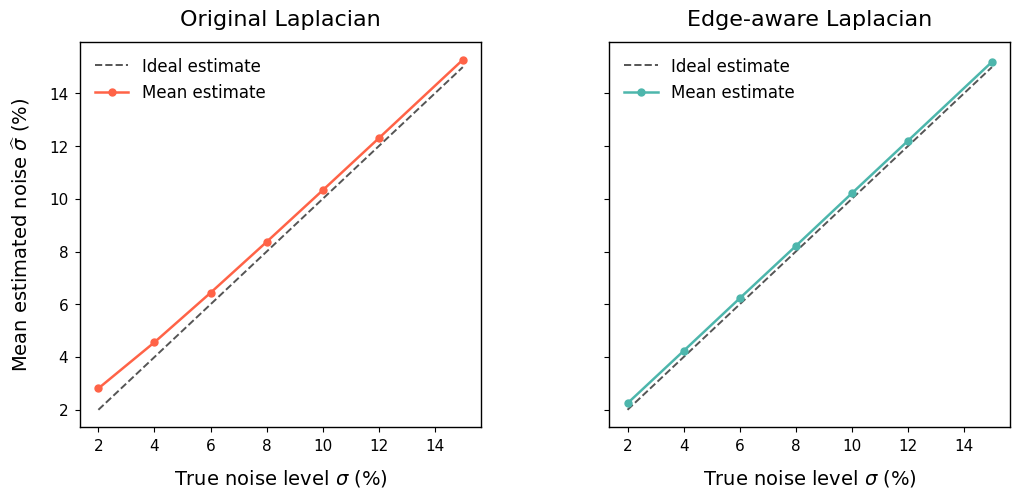

In [8]:
# Plot mean estimates against the ideal estimate
colours = {
    "Original Laplacian": "#ff6347",
    "Edge-aware Laplacian": "#4db6ac"
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, estimator_name in zip(axes, calibration_estimator_order):
    current = calibration_level_summary[
        calibration_level_summary["estimator_label"] == estimator_name
    ].sort_values("true_sigma")

    ax.plot(noise_levels, noise_levels, color="#555555", linestyle="--",
            linewidth=1.4, label="Ideal estimate")
    ax.plot(current["true_sigma"], current["mean_estimate"], marker="o",
            markersize=5, linewidth=1.8, color=colours[estimator_name],
            label="Mean estimate")

    ax.set_title(estimator_name, fontsize=16, pad=12)
    ax.tick_params(axis="both", labelsize=11, pad=5)
    ax.legend(frameon=False, fontsize=12, loc="upper left")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)

for ax in axes:
    ax.set_xlabel(r"True noise level $\sigma$ (%)", fontsize=14, labelpad=10)

axes[0].set_ylabel(r"Mean estimated noise $\widehat{\sigma}$ (%)", fontsize=14, labelpad=12)

fig.subplots_adjust(wspace=0.32)
fig.savefig(result_dir / "laplacian_calibration_estimate_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


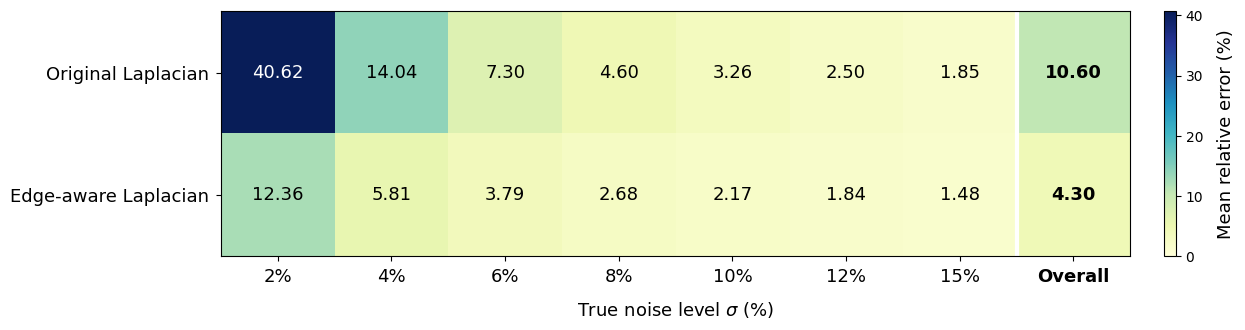

In [9]:
# Calibration MRE heatmap
calibration_heatmap_data = (
    calibration_level_summary.pivot(
        index="estimator_label", columns="true_sigma", values="mean_relative_error"
    )
    .reindex(index=calibration_estimator_order, columns=noise_levels)
)

calibration_heatmap_data["Overall"] = (
    calibration_comparison.set_index("estimator_label")
    .loc[calibration_estimator_order, "mean_relative_error"]
)

fig, ax = plt.subplots(figsize=(13.5, 3.4))
image = ax.imshow(calibration_heatmap_data.values, cmap="YlGnBu", aspect="auto", vmin=0)

x_labels = [f"{value}%" for value in noise_levels] + ["Overall"]
ax.set_xticks(np.arange(len(x_labels)), labels=x_labels)
ax.set_yticks(np.arange(len(calibration_estimator_order)), labels=calibration_estimator_order)
ax.set_xlabel(r"True noise level $\sigma$ (%)", fontsize=13, labelpad=10)
ax.tick_params(axis="both", labelsize=13, pad=5)

# Separate the overall column
ax.axvline(len(noise_levels) - 0.5, color="white", linewidth=3)
ax.get_xticklabels()[-1].set_fontweight("bold")

maximum_mre = calibration_heatmap_data.to_numpy().max()

for row in range(len(calibration_estimator_order)):
    for column in range(len(x_labels)):
        value = calibration_heatmap_data.iloc[row, column]
        text_colour = "white" if value > maximum_mre * 0.55 else "black"
        ax.text(
            column, row, f"{value:.2f}", ha="center", va="center",
            color=text_colour, fontsize=13,
            fontweight="bold" if column == len(x_labels) - 1 else "normal"
        )

colour_bar = fig.colorbar(image, ax=ax, pad=0.03)
colour_bar.set_label("Mean relative error (%)", fontsize=13, labelpad=10)
colour_bar.ax.tick_params(labelsize=10)

fig.tight_layout()
fig.savefig(result_dir / "laplacian_calibration_mre_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()
